# Training: Echo State Network mit PyTorch

---

## Was ist Reservoir Computing?

Ein **Echo State Network (ESN)** ist eine spezielle Klasse rekurrenter neuronaler Netze, die für die Verarbeitung von **Zeitreihen** entwickelt wurde. Im Gegensatz zu klassischen RNNs oder LSTMs wird beim ESN das interne Netzwerk (das sog. *Reservoir*) **zufällig initialisiert und danach nicht mehr verändert**. Nur die Ausgabeschicht wird trainiert.

### Warum ist das sinnvoll?

Bei klassischen RNNs muss das gesamte Netz — inklusive aller rekurrenten
Verbindungen — durch Backpropagation trainiert werden. Das führt zu drei
bekannten Problemen:

- **Vanishing Gradient** -> der Gradient wird über viele Zeitschritte
  exponentiell klein und das Netz lernt kaum noch
- **Langsames Training** -> jeder Parameter jeder Schicht muss angepasst werden
- **Lokale Minima** -> das Optimierungsproblem ist nichtkonvex, der Optimizer
  kann in suboptimalen Lösungen stecken bleiben

Das ESN umgeht alle drei Probleme.

Trainiert wird nur die **Ausgabeschicht `W_out`** — das ist eine einfache
lineare Regression:

- konvex → garantiert globales Minimum
- schnell → nur eine Schicht, keine Zeitschritte rückwärts
- stabil → kein Vanishing Gradient möglich


### Grundprinzip

**Schritt 1: Eingabe transformieren**  
Der aktuelle Messwert `u(t)` wird über die zufällige, fixe Matrix `W_in`
auf N Reservoir-Neuronen projiziert.

**Schritt 2: Gedächtnis aufbauen**  
Gleichzeitig fliesst der alte Reservoir-Zustand `x(t-1)` über die rekurrente
Matrix `W` zurück. Dadurch enthält `x(t)` eine nichtlineare Mischung aller
bisherigen Eingaben — das Reservoir hat ein **Gedächtnis**.

**Schritt 3: Zustand aktualisieren**  
Beide Anteile werden kombiniert und durch `tanh` auf `[-1, 1]` begrenzt:

$$x(t) = \tanh\bigl(W_{in} \cdot u(t) + W \cdot x(t-1)\bigr)$$

**Schritt 4: Vorhersage ausgeben**  
Die trainierbare Ausgabeschicht `W_out` liest den Zustand `x(t)` aus und
liefert die Vorhersage für den nächsten Zeitschritt:

$$y(t+1) = W_{out} \cdot x(t) + b$$

**Schritt 5: Nur `W_out` wird trainiert**  
`W_in` und `W` bleiben während des gesamten Trainings unverändert.
Das Modell lernt lediglich, welche Linearkombination der N Reservoir-Zustände
die beste Vorhersage liefert — mathematisch eine konvexe lineare Regression,
ohne Vanishing-Gradient-Problem.
- **`W_in`** — projiziert den skalaren Input auf N Reservoir-Neuronen (fix, zufällig)
- **`W`** — rekurrente Verbindungen im Reservoir (fix, dünn besetzt)
- **`W_out`** — lernbare Ausgabeschicht (nur diese wird trainiert)

### Aufbau dieses Notebooks

1. Imports & Daten laden
2. Dataset und DataLoader
3. ESN als `nn.Module` implementieren
4. Training mit MSE Loss und Adam Optimizer
5. Auswertung auf Testdaten
6. Hyperparameter-Suche: Optimale Reservoir-Grösse
7. Zusammenfassung


## 1. Imports und Daten laden

### Verwendete Bibliotheken

| Bibliothek | Wozu |
|---|---|
| `numpy` | Array-Operationen, Datei-I/O |
| `matplotlib` | Visualisierungen |
| `torch` | Tensor-Berechnungen, Autograd |
| `torch.nn` | Netzwerk-Bausteine (Linear, Module, Loss) |
| `torch.utils.data` | Dataset- und DataLoader-Infrastruktur |

### Gerät (Device)

PyTorch kann Berechnungen auf der **CPU** oder einer **GPU** (CUDA) ausführen. Mit `torch.device('cuda' if torch.cuda.is_available() else 'cpu')` wird automatisch die schnellste verfügbare Option gewählt. Alle Tensoren und Modelle müssen auf dasselbe Gerät verschoben werden (`.to(device)`), sonst entstehen Laufzeitfehler.

### Reproduzierbarkeit

`torch.manual_seed(42)` und `np.random.seed(42)` setzen den Zufallszahlengenerator auf einen fixen Wert. So sind die zufälligen Reservoir-Gewichte bei jedem Durchlauf identisch — wichtig für vergleichbare Experimente.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Gerät festlegen: GPU wenn vorhanden, sonst CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Verwendetes Gerät: {device}")

# Reproduzierbarkeit
torch.manual_seed(42)
np.random.seed(42)

# Daten aus Notebook 01 laden
train_data = np.load('data/oscillations.npy',      allow_pickle=True)
test_data  = np.load('data/oscillations_test.npy', allow_pickle=True)

print(f"Trainingsdaten: {len(train_data)} Schwingungen")
print(f"Testdaten:      {len(test_data)} Schwingungen")


Verwendetes Gerät: cpu
Trainingsdaten: 25 Schwingungen
Testdaten:      25 Schwingungen


## 2. Dataset und DataLoader

### PyTorch-Dateninfrastruktur

PyTorch trennt sauber zwischen *wie ein Sample aussieht* (`Dataset`) und *wie Samples an das Netz geliefert werden* (`DataLoader`):

```
Rohdaten  →  Dataset.__getitem__(idx)  →  DataLoader (Batches, Shuffle)  →  Training
```

- **`Dataset`** — definiert ein einzelnes Sample: hier ein Paar `(y(t), y(t+1))`
- **`DataLoader`** — liefert Batches, mischt die Reihenfolge (`shuffle=True`),   kann parallelisiert werden (`num_workers`)

### One-Step-Ahead-Prediction

Das Ziel ist: gegeben `y(t)`, vorhersage `y(t+1)`.
Aus einer Schwingung `[y₀, y₁, ..., y_T]` entstehen `T` unabhängige Samples:

```
t=0: Input=y₀  →  Target=y₁
t=1: Input=y₁  →  Target=y₂
...
t=T-1: Input=y_{T-1}  →  Target=y_T
```

**Wichtig:** Im Training werden die Samples als **unabhängig** behandelt — der Reservoir-Zustand `x` wird pro Batch zurückgesetzt. Nur bei der Auswertung (Abschnitt 5) wird der Zustand sequenziell weitergegeben.

### `unsqueeze(0)`

Jeder Wert `y(t)` ist ein Skalar (0-dimensional). `unsqueeze(0)` fügt eine Dimension hinzu → Form `(1,)`. Der DataLoader stapelt dann Batches zu Form `(batch, 1)`.


In [2]:
class OscillationDataset(Dataset):
    def __init__(self, oscillations):
        self.samples = []
        for osc in oscillations:
            y = torch.tensor(osc['y'], dtype=torch.float32)
            for t in range(len(y) - 1):
                # unsqueeze(0): Skalar → Vektor der Laenge 1, fuer Batch-Kompatibilitaet
                self.samples.append((y[t].unsqueeze(0), y[t+1].unsqueeze(0)))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]


train_dataset = OscillationDataset(train_data)
test_dataset  = OscillationDataset(test_data)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=256, shuffle=False)

print(f"Trainings-Samples: {len(train_dataset)}")
print(f"Test-Samples:      {len(test_dataset)}")
print(f"Batches pro Epoche: {len(train_loader)}")


Trainings-Samples: 24975
Test-Samples:      24975
Batches pro Epoche: 98


## 3. Echo State Network als `nn.Module`

### Architektur-Überblick

| Komponente | Typ | Form | Trainierbar? |
|---|---|---|---|
| `W_in` | `register_buffer` | `(N, 1)` | Nein |
| `W` | `register_buffer` | `(N, N)` | Nein |
| `W_out` | `nn.Linear(N, 1)` | `(1, N)` + Bias | **Ja** |

### `register_buffer` vs. `nn.Parameter`

- **`nn.Parameter`** — wird von PyTorch als trainierbarer Parameter registriert,   erscheint in `model.parameters()`, bekommt Gradienten
- **`register_buffer`** — Teil des Modells (wird gespeichert, auf Device verschoben),   aber **kein Gradient**, erscheint nicht in `model.parameters()`

Das Reservoir `W` und `W_in` werden als Buffer registriert: Sie sind fix und sollen nicht durch Backpropagation verändert werden.

### Spectral Radius

Der **Spektralradius** ist der grösste Betrag aller Eigenwerte von `W`.
Er kontrolliert das *Echo State Property*:

- **< 1** — Eingaben vergessen sich exponentiell → kurzes Gedächtnis
- **≈ 1** — Grenze der Stabilität → langes Gedächtnis
- **> 1** — Reservoir divergiert (instabil)

Typisch: `0.8 – 0.99`. In diesem Notebook: `0.95`.

### Sparsity

Nur ein Bruchteil der Reservoir-Gewichte ist von Null verschieden.
`sparsity=0.1` bedeutet: 10% der Verbindungen sind aktiv, 90% sind Null.
Dies ahmt die sparse Konnektivität biologischer Netze nach und verbessert oft die Generalisierung.

### Forward-Pass (ein Zeitschritt)

```
x(t) = tanh( W_in · u(t)  +  W · x(t-1) )
                ↑ Input-Anteil    ↑ Rekurrenter Anteil (Gedächtnis)

y(t+1) = W_out · x(t) + bias
```

Die `tanh`-Aktivierung begrenzt den Zustand auf `[-1, 1]` und verhindert, dass das Reservoir explodiert.


In [3]:
class EchoStateNetwork(nn.Module):

    def __init__(self, n_reservoir=300, spectral_radius=0.9, sparsity=0.1, verbose=True):
        super().__init__()
        self.n_reservoir = n_reservoir

        # --- Eingabe-Gewichte W_in (fix) ---
        W_in = torch.empty(n_reservoir, 1).uniform_(-1, 1)
        self.register_buffer('W_in', W_in)

        # --- Reservoir-Gewichte W (fix, sparse) ---
        W = torch.empty(n_reservoir, n_reservoir).uniform_(-1, 1)
        self.W: torch.Tensor
        mask = torch.rand_like(W) > sparsity
        W[mask] = 0.0
        eigenvalues = torch.linalg.eigvals(W)
        current_radius = eigenvalues.abs().max()
        W = W * (spectral_radius / current_radius.item())
        self.register_buffer('W', W)

        # --- Ausgabeschicht W_out (trainierbar) ---
        self.W_out = nn.Linear(n_reservoir, 1)

        if verbose:
            trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
            total     = sum(p.numel() for p in self.parameters()) + sum(b.numel() for b in self.buffers())
            print(f"ESN: {n_reservoir} Neuronen | Trainierbar: {trainable} / {total} Parameter")

    def forward(self, u, x=None):
        batch = u.shape[0]
        if x is None:
            x = torch.zeros(batch, self.n_reservoir, device=u.device)

        # x(t) = tanh( W_in * u(t) + W * x(t-1) )
        x = torch.tanh(
            u @ self.W_in.T +
            x @ self.W.T
        )

        # y(t+1) = W_out * x(t)
        y = self.W_out(x)
        return y, x


# Standard-Modell fuer Abschnitte 4 & 5
model = EchoStateNetwork(n_reservoir=300, spectral_radius=0.95, sparsity=0.1).to(device)


ESN: 300 Neuronen | Trainierbar: 301 / 90601 Parameter


## 4. Training

### Loss-Funktion: MSE

Der **Mean Squared Error** (mittlerer quadratischer Fehler) misst die durchschnittliche quadratische Abweichung zwischen Vorhersage `ŷ` und Zielwert `y`:

$$\text{MSE} = \frac{1}{B} \sum_{i=1}^{B} (\hat{y}_i - y_i)^2$$

Quadrieren bestraft grosse Fehler stärker als kleine — sinnvoll für Regressionsaufgaben.

### Optimizer: Adam

**Adam** (*Adaptive Moment Estimation*) passt die Lernrate für jeden Parameter individuell an, basierend auf dem gleitenden Mittelwert der Gradienten (Moment 1) und der quadrierten Gradienten (Moment 2). Vorteile gegenüber SGD:

- Robuster gegenüber der Wahl der Lernrate
- Konvergiert oft schneller
- Gut für sparse Gradienten

### Training-Schleife

```
Für jede Epoche:
  Für jeden Batch (u, target):
    1. Vorwärtspass: pred = model(u)        ← forward() aufgerufen
    2. Loss berechnen: L = MSE(pred, target)
    3. Gradienten nullen: optimizer.zero_grad()
    4. Rückwärtspass: loss.backward()       ← Gradient nur durch W_out
    5. Update: optimizer.step()             ← nur W_out wird verändert
```

**Wichtig:** Da nur `W_out` trainierbar ist, fliesst der Gradient ausschliesslich durch die lineare Ausgabeschicht — das Reservoir `W` und `W_in` bleiben unverändert.


Epoche  1/20 — Loss: 0.015437
Epoche  2/20 — Loss: 0.012411
Epoche  3/20 — Loss: 0.011677
Epoche  4/20 — Loss: 0.011437
Epoche  5/20 — Loss: 0.011514
Epoche  6/20 — Loss: 0.011415
Epoche  7/20 — Loss: 0.011408
Epoche  8/20 — Loss: 0.011488
Epoche  9/20 — Loss: 0.011552
Epoche 10/20 — Loss: 0.011538
Epoche 11/20 — Loss: 0.011519
Epoche 12/20 — Loss: 0.011413
Epoche 13/20 — Loss: 0.011522
Epoche 14/20 — Loss: 0.011390
Epoche 15/20 — Loss: 0.011392
Epoche 16/20 — Loss: 0.011446
Epoche 17/20 — Loss: 0.011404
Epoche 18/20 — Loss: 0.011410
Epoche 19/20 — Loss: 0.011387
Epoche 20/20 — Loss: 0.011403


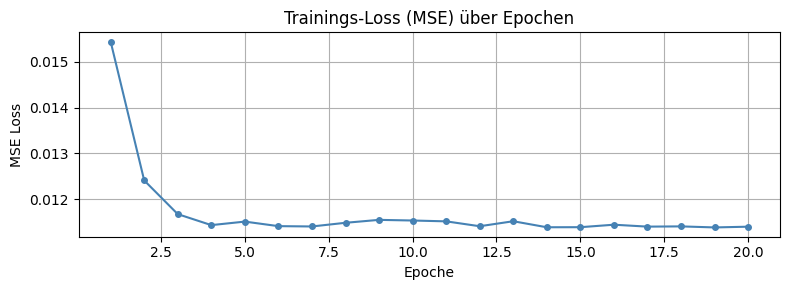

In [4]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

N_EPOCHS = 20
train_losses = []

model.train()
for epoch in range(N_EPOCHS):
    epoch_loss = 0.0

    for u_batch, target_batch in train_loader:
        u_batch      = u_batch.to(device)
        target_batch = target_batch.to(device)

        # Reservoir-Zustand pro Batch zuruecksetzen (x=None → Nullvektor)
        pred, _ = model(u_batch)

        loss = criterion(pred, target_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(f"Epoche {epoch+1:2d}/{N_EPOCHS} — Loss: {avg_loss:.6f}")

plt.figure(figsize=(8, 3))
plt.plot(range(1, N_EPOCHS+1), train_losses, marker='o', markersize=4, color='steelblue')
plt.title('Trainings-Loss (MSE) über Epochen')
plt.xlabel('Epoche')
plt.ylabel('MSE Loss')
plt.grid(True)
plt.tight_layout()
plt.show()


## 5. Auswertung auf Testdaten

### Sequenzielle Inferenz

Im Training wurden Zeitschritte als unabhängige Samples behandelt. Bei der **Auswertung** lassen wir das Modell die Schwingung sequenziell durchlaufen: Der Reservoir-Zustand `x` wird von Schritt zu Schritt **weitergereicht** — so kann das ESN sein zeitliches Gedächtnis nutzen.

```
t=0: u=y₀, x=0    → pred₀, x₁
t=1: u=y₁, x=x₁   → pred₁, x₂
...
t=T: u=y_T, x=x_T → pred_T, x_{T+1}
```

### Warmup-Phase

Die ersten `WARMUP=100` Zeitschritte werden **ignoriert**. In dieser Phase "erwärmt" sich das Reservoir: Der Zustand `x` konvergiert von Null zu einem informationstragenden Zustand, der die bisherige Eingabe reflektiert. Vorhersagen in dieser Phase wären unzuverlässig.

### Fehlermetrik: RMSE

Der **Root Mean Squared Error** ist die Wurzel des MSE — er hat dieselbe Einheit wie die Zielgrösse und ist intuitiver interpretierbar:

$$\text{RMSE} = \sqrt{\frac{1}{N}\sum_{t=1}^{N}(\hat{y}_t - y_t)^2}$$

### `torch.no_grad()`

Bei der Auswertung werden **keine Gradienten** benötigt. `torch.no_grad()` deaktiviert das Autograd-System → weniger Speicher, schnellere Ausführung.


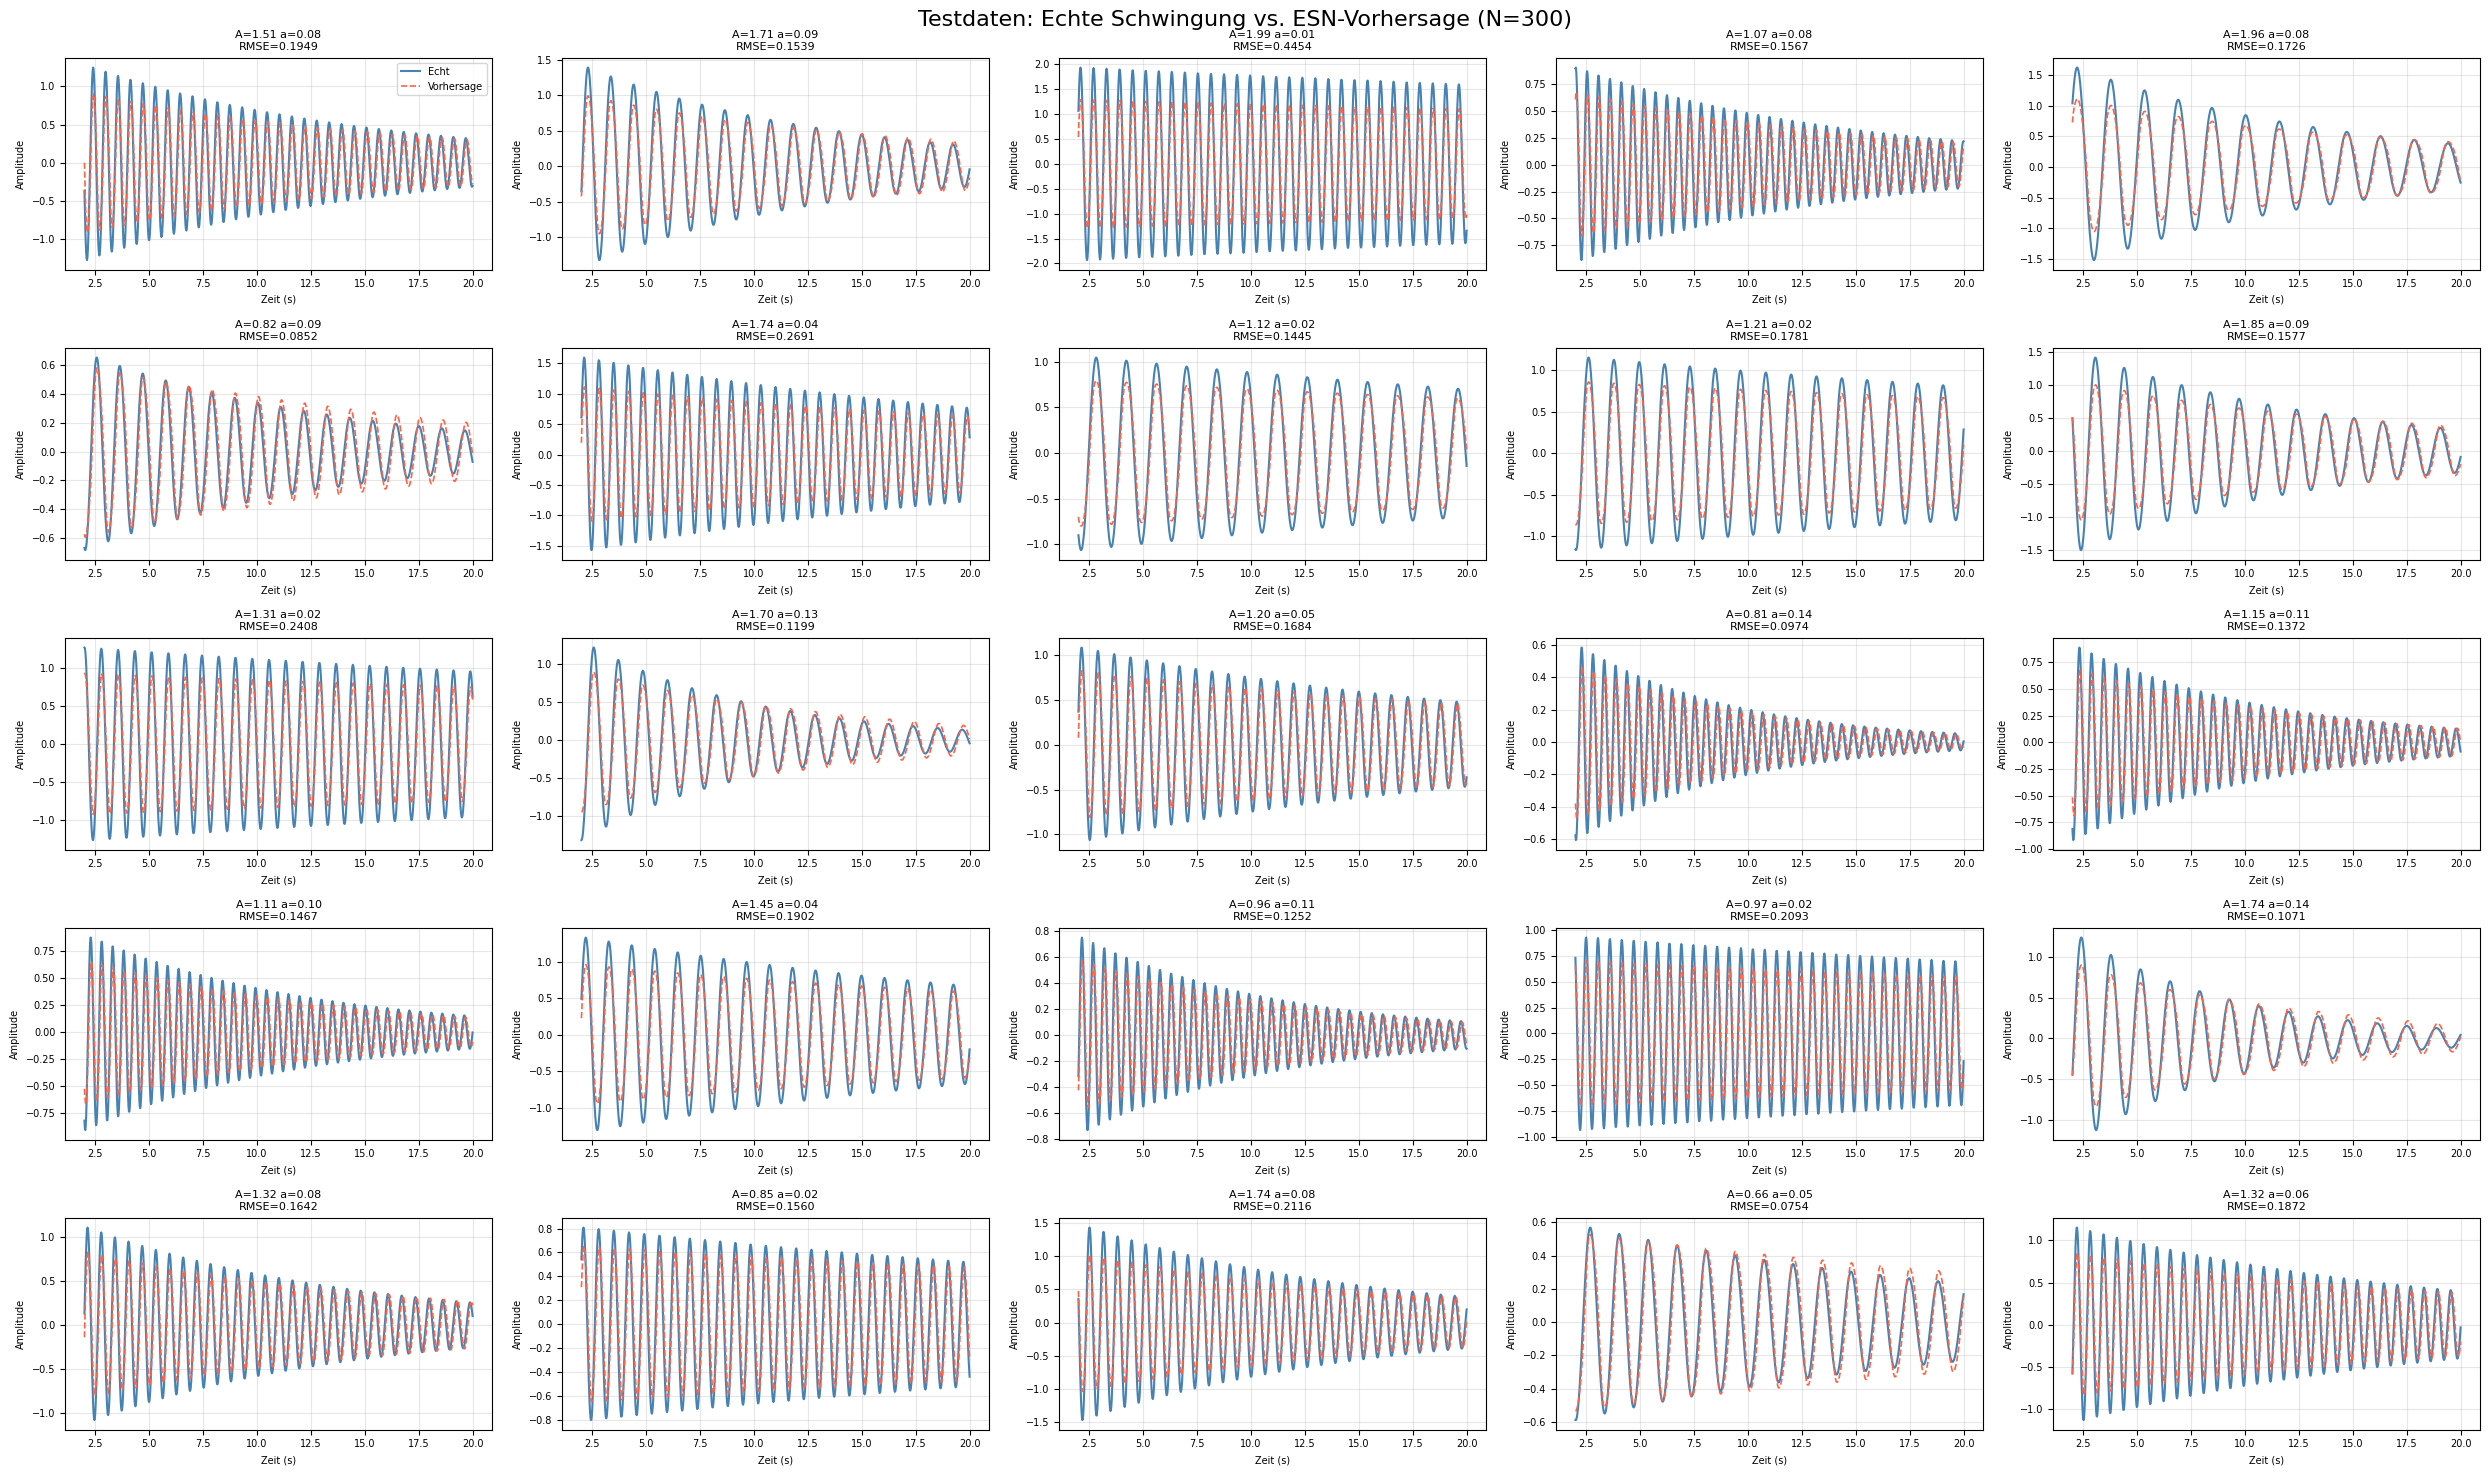

Durchschnittlicher RMSE: 0.17179
Bester RMSE:             0.07544
Schlechtester RMSE:      0.44536


In [6]:
WARMUP = 100

def evaluate_model(mdl, data, warmup=WARMUP):
    """Wertet ein ESN sequenziell auf allen Schwingungen aus. Gibt RMSE-Liste zurueck."""
    mdl.eval()
    rmse_list = []
    with torch.no_grad():
        for osc in data:
            y_np     = osc['y']
            y_tensor = torch.tensor(y_np, dtype=torch.float32, device=device)

            x = None
            preds = []
            for t in range(len(y_tensor) - 1):
                u = y_tensor[t].view(1, 1)
                pred, x = mdl(u, x)
                preds.append(pred.item())

            preds  = np.array(preds)
            y_ref  = y_np[warmup + 1:]
            y_pred = preds[warmup:]
            rmse_list.append(np.sqrt(np.mean((y_pred - y_ref) ** 2)))
    return rmse_list


rmse_list = evaluate_model(model, test_data)

# --- Visualisierung aller 25 Testschwingungen ---
fig, axes = plt.subplots(5, 5, figsize=(25, 15))
fig.suptitle("Testdaten: Echte Schwingung vs. ESN-Vorhersage (N=300)", fontsize=16)
axes = axes.flatten()

model.eval()
with torch.no_grad():
    for i, osc in enumerate(test_data):
        y_np     = osc['y']
        t_np     = osc['t']
        y_tensor = torch.tensor(y_np, dtype=torch.float32, device=device)

        x = None
        preds = []
        for t in range(len(y_tensor) - 1):
            u = y_tensor[t].view(1, 1)
            pred, x = model(u, x)
            preds.append(pred.item())

        preds  = np.array(preds)
        y_ref  = y_np[WARMUP + 1:]
        y_pred = preds[WARMUP:]
        t_plot = t_np[WARMUP + 1:]

        axes[i].plot(t_plot, y_ref,  label='Echt',       color='steelblue', linewidth=1.5)
        axes[i].plot(t_plot, y_pred, label='Vorhersage', color='tomato',    linewidth=1.2, linestyle='--')
        p = osc['params']
        axes[i].set_title(f"A={p['A']:.2f} a={p['α']:.2f}\nRMSE={rmse_list[i]:.4f}", fontsize=8)
        axes[i].set_xlabel('Zeit (s)', fontsize=7)
        axes[i].set_ylabel('Amplitude', fontsize=7)
        axes[i].tick_params(labelsize=7)
        axes[i].grid(True, alpha=0.3)
        if i == 0:
            axes[i].legend(fontsize=7)

plt.tight_layout()
plt.show()

print(f"Durchschnittlicher RMSE: {np.mean(rmse_list):.5f}")
print(f"Bester RMSE:             {np.min(rmse_list):.5f}")
print(f"Schlechtester RMSE:      {np.max(rmse_list):.5f}")


## 6. Hyperparameter-Suche: Optimale Reservoir-Grösse

### Fragestellung

Wie viele Neuronen braucht das Reservoir, um gute Vorhersagen zu liefern?

- **Zu wenig Neuronen** → das Reservoir kann die Dynamik nicht ausreichend   repräsentieren → hoher Fehler (*Underfitting*)
- **Zu viele Neuronen** → mehr Kapazität, aber höherer Rechenaufwand;   ab einem Punkt kein weiterer Gewinn (*diminishing returns*)

### Vorgehen

Für jede Reservoir-Grösse `N` in `[10, 25, 50, 100, 200, 300, 500, 750, 1000]`:

1. Ein neues ESN mit `n_reservoir=N` erstellen (selber Seed → vergleichbar)
2. **20 Epochen** auf den Trainingsdaten trainieren
3. Den mittleren RMSE auf den **Testdaten** berechnen
4. Ergebnisse speichern und visualisieren

### Komplexität

Die Anzahl trainierbarer Parameter wächst **linear** mit N:

$$\text{Parameter}_{W_{out}} = N + 1 \quad (N \text{ Gewichte} + 1 \text{ Bias})$$

Die Reservoir-Matrizen selbst (`W`: `N×N`) wachsen **quadratisch** — aber sie werden nicht trainiert.


Nach einem schnellen Abfall flacht der RMSE typischerweise ab — es gibt einen *Sweet Spot*, jenseits dessen zusätzliche Neuronen keinen signifikanten Vorteil mehr bringen.


In [7]:
def train_and_evaluate(n_reservoir, n_epochs=20, lr=1e-3,
                       spectral_radius=0.95, sparsity=0.1):
    """Erstellt, trainiert und evaluiert ein ESN. Gibt (mean_rmse, loss_history) zurueck."""
    torch.manual_seed(42)

    mdl = EchoStateNetwork(
        n_reservoir=n_reservoir,
        spectral_radius=spectral_radius,
        sparsity=sparsity,
        verbose=False,
    ).to(device)

    opt     = torch.optim.Adam(mdl.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    losses  = []

    mdl.train()
    for epoch in range(n_epochs):
        epoch_loss = 0.0
        for u_batch, target_batch in train_loader:
            u_batch      = u_batch.to(device)
            target_batch = target_batch.to(device)
            pred, _ = mdl(u_batch)
            loss = loss_fn(pred, target_batch)
            opt.zero_grad()
            loss.backward()
            opt.step()
            epoch_loss += loss.item()
        losses.append(epoch_loss / len(train_loader))

    rmse_scores = evaluate_model(mdl, test_data)
    mean_rmse   = float(np.mean(rmse_scores))
    print(f"  N={n_reservoir:5d} | RMSE={mean_rmse:.5f} | Final-Loss={losses[-1]:.6f}")
    return mean_rmse, losses, mdl


# ── Suchraum ─────────────────────────────────────────────────────────────────
reservoir_sizes = [10, 25, 50, 100, 200, 300, 500, 750, 1000]

print("Starte Hyperparameter-Suche...")
print(f"{'N':>6} | {'RMSE':>10} | {'Final-Loss':>12}")
print("-" * 36)

results    = {}
all_losses = {}
models     = {}

for N in reservoir_sizes:
    mean_rmse, losses, mdl = train_and_evaluate(N, n_epochs=20)
    results[N]    = mean_rmse
    all_losses[N] = losses
    models[N]     = mdl

print("-" * 36)
best_N    = min(results, key=results.get)
best_rmse = results[best_N]
print(f"Beste Reservoir-Grösse: N={best_N}  →  RMSE={best_rmse:.5f}")


Starte Hyperparameter-Suche...
     N |       RMSE |   Final-Loss
------------------------------------
  N=   10 | RMSE=0.13988 | Final-Loss=0.012960
  N=   25 | RMSE=0.19140 | Final-Loss=0.012114
  N=   50 | RMSE=0.07752 | Final-Loss=0.011762
  N=  100 | RMSE=0.11348 | Final-Loss=0.011368
  N=  200 | RMSE=0.14897 | Final-Loss=0.011351
  N=  300 | RMSE=0.17179 | Final-Loss=0.011403
  N=  500 | RMSE=0.19043 | Final-Loss=0.011484
  N=  750 | RMSE=0.23291 | Final-Loss=0.011612
  N= 1000 | RMSE=0.17339 | Final-Loss=0.011779
------------------------------------
Beste Reservoir-Grösse: N=50  →  RMSE=0.07752


## 6b. Ergebnisse der Hyperparameter-Suche

Die folgenden vier Diagramme zeigen:

1. **RMSE vs. Reservoir-Grösse** — Wie gut ist das Modell als Funktion von N?
   Das Optimum ist markiert.
2. **Trainings-Loss-Verlauf** — Wie schnell und wie tief konvergiert das Training?
   Grössere Reservoirs haben mehr Kapazität und erreichen oft tiefere Loss-Werte.
3. **Trainierbare Parameter vs. N** — Der Rechenaufwand des Trainings
   (nur `W_out` wird trainiert → lineares Wachstum).
4. **RMSE-Verteilung für das optimale Modell** — Wie konsistent ist die beste Konfiguration
   über die 25 verschiedenen Testschwingungen?


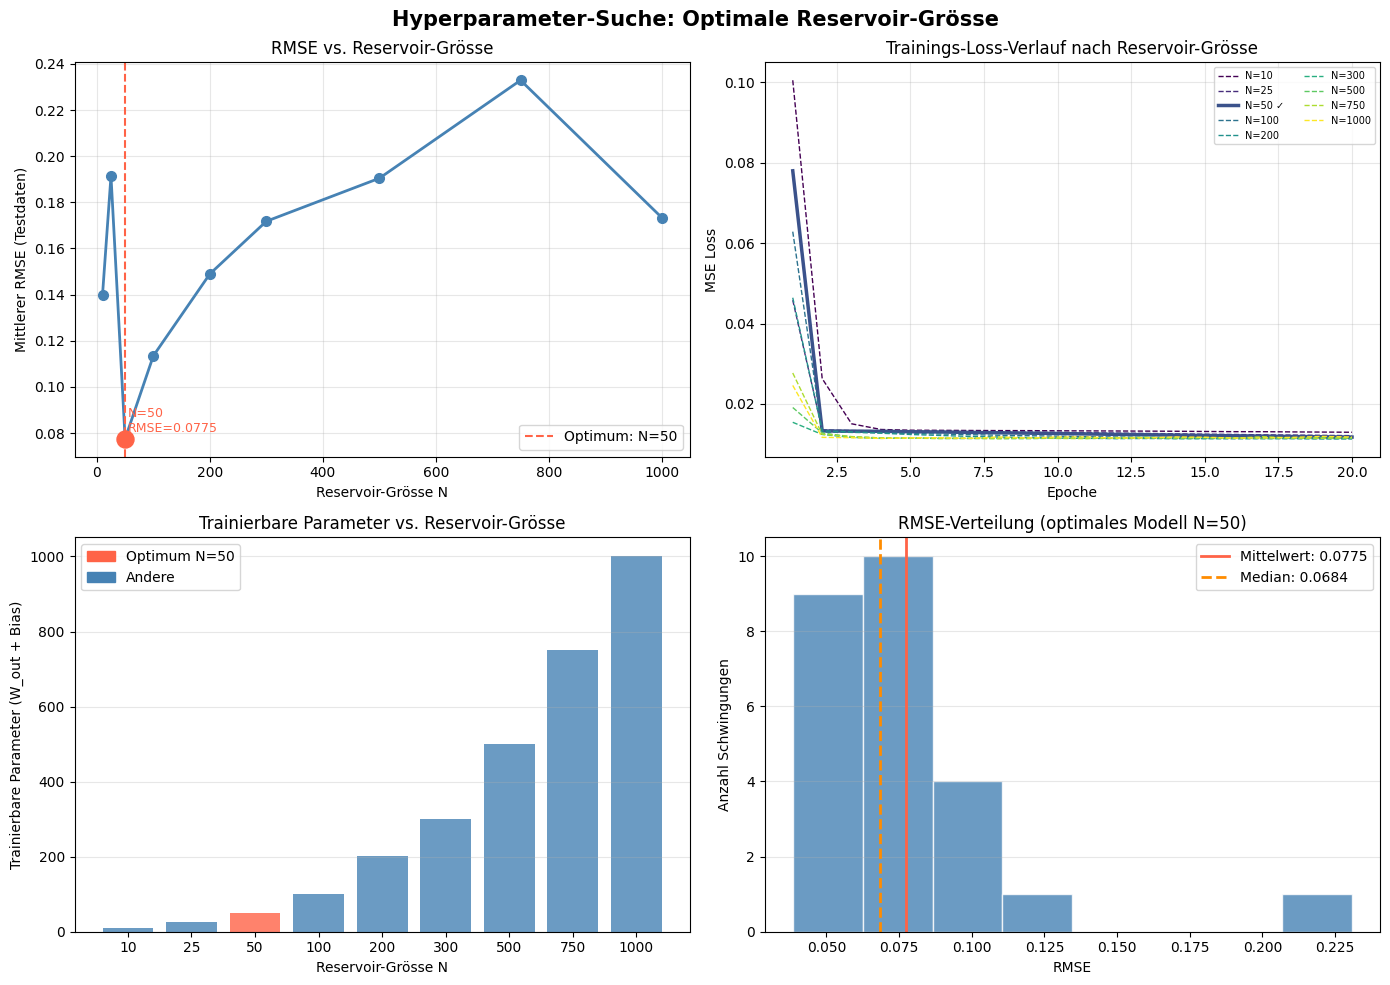


=== Ergebnistabelle ===
     N |       RMSE |  Parameter
---------------------------------
    10 |    0.13988 |         11
    25 |    0.19140 |         26
    50 |    0.07752 |         51 <- BEST
   100 |    0.11348 |        101
   200 |    0.14897 |        201
   300 |    0.17179 |        301
   500 |    0.19043 |        501
   750 |    0.23291 |        751
  1000 |    0.17339 |       1001


In [8]:
Ns       = list(results.keys())
rmses    = [results[n] for n in Ns]
n_params = [n + 1 for n in Ns]  # W_out: N Gewichte + 1 Bias

best_N    = min(results, key=results.get)
best_rmse = results[best_N]
best_idx  = Ns.index(best_N)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Hyperparameter-Suche: Optimale Reservoir-Grösse", fontsize=15, fontweight='bold')

# --- Plot 1: RMSE vs N ---
ax = axes[0, 0]
ax.plot(Ns, rmses, marker='o', color='steelblue', linewidth=2, markersize=7)
ax.axvline(best_N, color='tomato', linestyle='--', linewidth=1.5,
           label=f'Optimum: N={best_N}')
ax.scatter([best_N], [best_rmse], color='tomato', s=150, zorder=5)
ax.annotate(f'N={best_N}\nRMSE={best_rmse:.4f}',
            xy=(best_N, best_rmse),
            xytext=(best_N * 1.1, best_rmse * 1.04),
            fontsize=9, color='tomato',
            arrowprops=dict(arrowstyle='->', color='tomato', lw=1.2))
ax.set_xlabel('Reservoir-Grösse N')
ax.set_ylabel('Mittlerer RMSE (Testdaten)')
ax.set_title('RMSE vs. Reservoir-Grösse')
ax.legend()
ax.grid(True, alpha=0.3)

# --- Plot 2: Trainings-Loss-Kurven ---
ax = axes[0, 1]
cmap = plt.cm.viridis(np.linspace(0, 1, len(reservoir_sizes)))
for idx, N in enumerate(reservoir_sizes):
    lw = 2.5 if N == best_N else 1.0
    ls = '-'  if N == best_N else '--'
    label = f'N={N}' + (' ✓' if N == best_N else '')
    ax.plot(range(1, 21), all_losses[N], color=cmap[idx],
            linewidth=lw, linestyle=ls, label=label)
ax.set_xlabel('Epoche')
ax.set_ylabel('MSE Loss')
ax.set_title('Trainings-Loss-Verlauf nach Reservoir-Grösse')
ax.legend(fontsize=7, ncol=2)
ax.grid(True, alpha=0.3)

# --- Plot 3: Trainierbare Parameter vs N ---
ax = axes[1, 0]
colors_bar = ['tomato' if n == best_N else 'steelblue' for n in Ns]
bars = ax.bar(range(len(Ns)), n_params, color=colors_bar, alpha=0.8)
ax.set_xticks(range(len(Ns)))
ax.set_xticklabels([str(n) for n in Ns])
ax.set_xlabel('Reservoir-Grösse N')
ax.set_ylabel('Trainierbare Parameter (W_out + Bias)')
ax.set_title('Trainierbare Parameter vs. Reservoir-Grösse')
# Legende manuell
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='tomato',    label=f'Optimum N={best_N}'),
    Patch(color='steelblue', label='Andere')
])
ax.grid(True, alpha=0.3, axis='y')

# --- Plot 4: RMSE-Verteilung fuer optimales N ---
ax = axes[1, 1]
best_rmse_all = evaluate_model(models[best_N], test_data)
ax.hist(best_rmse_all, bins=8, color='steelblue', alpha=0.8, edgecolor='white')
ax.axvline(np.mean(best_rmse_all), color='tomato', linewidth=2,
           label=f'Mittelwert: {np.mean(best_rmse_all):.4f}')
ax.axvline(np.median(best_rmse_all), color='darkorange', linewidth=2, linestyle='--',
           label=f'Median: {np.median(best_rmse_all):.4f}')
ax.set_xlabel('RMSE')
ax.set_ylabel('Anzahl Schwingungen')
ax.set_title(f'RMSE-Verteilung (optimales Modell N={best_N})')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Zusammenfassungstabelle
print("\n=== Ergebnistabelle ===")
print(f"{'N':>6} | {'RMSE':>10} | {'Parameter':>10}")
print("-" * 33)
for N in Ns:
    marker = " <- BEST" if N == best_N else ""
    print(f"{N:>6} | {results[N]:>10.5f} | {N+1:>10}{marker}")


## 7. Zusammenfassung

### Was wurde in diesem Notebook gemacht?

| Abschnitt | Inhalt |
|---|---|
| 1 | Imports, Gerät-Setup, Daten laden |
| 2 | `Dataset` / `DataLoader` für One-Step-Ahead-Prediction |
| 3 | ESN-Architektur mit fixem Reservoir und trainierbarem `W_out` |
| 4 | Training mit MSE Loss und Adam Optimizer |
| 5 | Sequenzielle Auswertung mit Warmup-Phase, RMSE-Metrik |
| 6 | Hyperparameter-Suche über Reservoir-Grössen |

### Wichtige PyTorch-Konzepte

| Konzept | Wozu verwendet |
|---|---|
| `nn.Module` | Basisklasse für das ESN |
| `register_buffer` | Fixer Tensor ohne Gradient: `W`, `W_in` |
| `nn.Linear` | Trainierbare Ausgabeschicht `W_out` |
| `nn.MSELoss` | Verlustfunktion für Regression |
| `torch.optim.Adam` | Adaptiver Optimizer |
| `Dataset` / `DataLoader` | Effizientes Laden in Batches |
| `model.train()` / `model.eval()` | Trainings- vs. Auswertungsmodus |
| `torch.no_grad()` | Kein Gradient bei Auswertung |

### Erkenntnisse aus der Hyperparameter-Suche

- Ab einer bestimmten Reservoir-Grösse flacht der RMSE ab (*diminishing returns*)
- Sehr kleine Reservoirs (< 50) können die Schwingungsdynamik nicht ausreichend enkodieren
- Die Anzahl trainierbarer Parameter wächst nur **linear** mit N — das Modell bleibt stets kompakt
- `spectral_radius` und `sparsity` wurden fix gehalten;   diese könnten in einer weiteren Suche ebenfalls optimiert werden

### Weitere Hyperparameter zum Experimentieren

| Parameter | Effekt |
|---|---|
| `n_reservoir` | Mehr → mehr Kapazität, aber höherer Rechenaufwand |
| `spectral_radius` | Näher an 1 → längeres Gedächtnis |
| `sparsity` | Mehr Nullen → biologisch plausibler, oft robuster |
| `N_EPOCHS` | Mehr → besseres Training (Vorsicht: Overfitting) |
| `lr` in Adam | Kleiner → stabiler aber langsamer |
| `WARMUP` | Grösser → zuverlässigerer Zustand, weniger Auswertungsdaten |
